# Milestone 2: exploratory data analysis and preprocessing

Group 2, Socratic AI Tutor. This notebook looks at every dataset we prepared, shows sample records, and explains
**what** each preprocessing step does and **why** we chose it. It reads the prepared files, it does not rebuild
them (the scripts in `notes/sandeep/milestone-2/data/scripts/` do that).

Two prepared versions exist (see the report, Section 6): **version A** (Sandeep Nalla, scripts) and
**version B** (Hariom Pandey, Colab). The notebook covers both.

Raw files and the NCERT text are not committed (size and licence). To rebuild: follow
`notes/sandeep/milestone-2/data/README.md`, then run this notebook from `docs/milestone-2/`.

In [1]:
import json
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.figsize": (7, 3.4), "axes.spines.top": False, "axes.spines.right": False})
A = Path("../../notes/sandeep/milestone-2/data")
B = Path("../../notes/hariom pandey/milestone-2")
P = A / "processed"

def jsonl(path):
    with open(path, encoding="utf8") as f:
        return [json.loads(line) for line in f]

## 1. ASSISTments, version A (learner model)

**What it is.** One row per answer: which student, which skill, right or wrong on the first try.
We use it to train the learner model (DKT) that predicts the chance of a correct answer on each skill.

**Preprocessing and why**

| Step | Why |
|---|---|
| Sort each student's answers by `order_id` | DKT reads a history in time order; shuffling would destroy the signal. |
| Drop answers with no skill label (63,755) | DKT tracks skills; an answer with no skill cannot update any. |
| Drop students with fewer than 3 answers | Too little history to learn from; same rule as the pyKT benchmark, so scores are comparable with published ones. |
| Number skills 0..148 | The model needs a contiguous index. We did not merge skills, so no information is lost. |
| Cut long histories into windows of at most 200 answers | Fixed-size input for batching. A hard cut at 200 would throw away answers; windows keep them all. |
| Split **by student** (80/10/10) | If one student were in two splits, the model could memorise that student and the test score would be too high. |

`drop_duplicates(order_id)` is also applied. In this corrected file every `order_id` is already unique, so it removes no rows
(checked below). It matters only for the uncorrected file, where one answer can appear once per skill.

In [2]:
stats = json.load(open(P / "assistments/stats.json"))
splits = {s: jsonl(P / f"assistments/{s}.jsonl") for s in ("train", "val", "test")}
skill_map = pd.read_csv(P / "assistments/skill_map.csv")
names = dict(zip(skill_map.skill, skill_map.skill_name))

raw = pd.read_csv(A / "raw/assistments/skill_builder_data_corrected.csv", encoding="latin1", low_memory=False,
                  usecols=["order_id", "user_id", "skill_id"])
print("raw rows:", len(raw), "| unique order_id:", raw.order_id.nunique(), "-> rows removed by the order_id dedup:", len(raw) - raw.order_id.nunique())

rows = []
for s, recs in splits.items():
    n = sum(len(r["skills"]) for r in recs)
    rows.append({"split": s, "students": len({r["user_id"] for r in recs}), "windows": len(recs), "answers": n,
                 "correct_rate": round(sum(sum(r["correct"]) for r in recs) / n, 3)})
pd.DataFrame(rows)

raw rows: 346860 | unique order_id: 346860 -> rows removed by the order_id dedup: 0


,split,students,windows,answers,correct_rate
0,train,3081,3571,228924,0.659
1,val,385,449,28037,0.664
2,test,386,434,25644,0.648


In [3]:
print("First training window (student %d, first 10 of %d answers):" % (splits["train"][0]["user_id"], len(splits["train"][0]["skills"])))
for k, c in list(zip(splits["train"][0]["skills"], splits["train"][0]["correct"]))[:10]:
    print(f"  skill {k:3d}  {names[k][:40]:40s}  correct={c}")

First training window (student 14, first 10 of 19 answers):
  skill 136  Circle Graph                              correct=0
  skill 136  Circle Graph                              correct=1
  skill 136  Circle Graph                              correct=0
  skill 136  Circle Graph                              correct=0
  skill 136  Circle Graph                              correct=0
  skill 136  Circle Graph                              correct=0
  skill 144  Circle Graph                              correct=0
  skill 137  Circle Graph                              correct=0
  skill 135  Circle Graph                              correct=1
  skill 137  Circle Graph                              correct=0


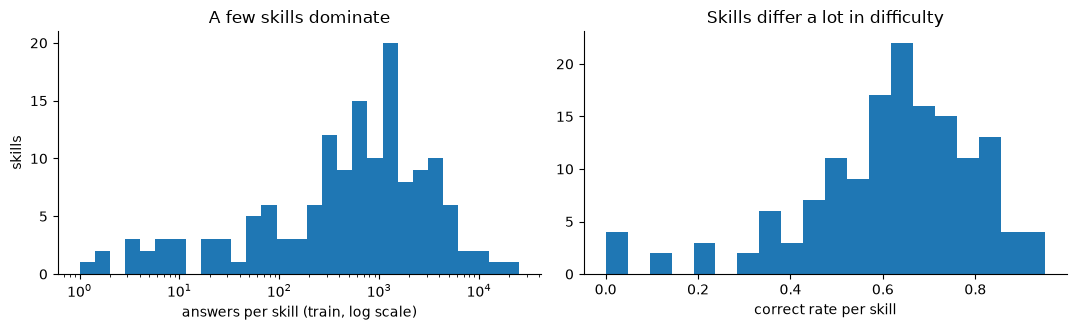

skills with fewer than 100 train answers: 33 of 149


,name,attempts,rate
85,Equation Solving Two or Fewer Steps,19738,0.68
23,Conversion of Fraction Decimals Percents,15332,0.64
66,Addition and Subtraction Integers,10896,0.59
69,Addition and Subtraction Fractions,8948,0.67
86,Equation Solving More Than Two Steps,6650,0.76
38,Proportion,6540,0.64
68,Multiplication and Division Integers,5830,0.78
9,Probability of a Single Event,5421,0.73


In [4]:
att, cor = Counter(), Counter()
for r in splits["train"]:
    for s, c in zip(r["skills"], r["correct"]):
        att[s] += 1; cor[s] += c
skills = pd.DataFrame({"attempts": att, "correct": cor}).fillna(0)
skills["rate"] = skills.correct / skills.attempts
skills["name"] = [names[i] for i in skills.index]

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].hist(skills.attempts, bins=np.logspace(0, 4.4, 30)); ax[0].set_xscale("log")
ax[0].set_xlabel("answers per skill (train, log scale)"); ax[0].set_ylabel("skills")
ax[0].set_title("A few skills dominate")
ax[1].hist(skills.rate, bins=20); ax[1].set_xlabel("correct rate per skill"); ax[1].set_title("Skills differ a lot in difficulty")
plt.tight_layout(); plt.show()
print("skills with fewer than 100 train answers:", int((skills.attempts < 100).sum()), "of", len(skills))
skills.sort_values("attempts", ascending=False).head(8)[["name", "attempts", "rate"]].round(2)

**Reading it.** The most practised skill has about 20,000 answers while 33 of 149 skills have fewer than 100. A DKT model will
therefore be much more reliable on common skills; rare skills need care in evaluation (report per-skill scores, not only one AUC).
Per-skill correct rates range widely, so skill identity alone already predicts a lot. That is why a simple per-skill accuracy baseline is
the first thing the learned model must beat.

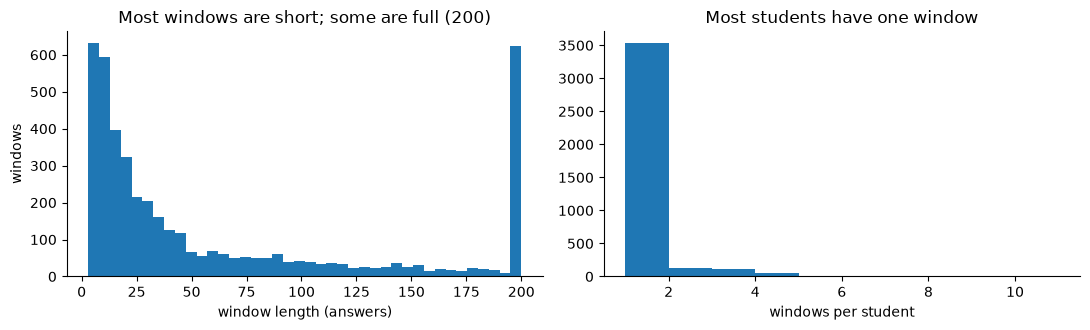

share of windows at the 200 cap: 13.8%


In [5]:
lens = pd.Series([len(r["skills"]) for recs in splits.values() for r in recs])
per_student = pd.Series(Counter(r["user_id"] for recs in splits.values() for r in recs))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].hist(lens, bins=40); ax[0].set_xlabel("window length (answers)"); ax[0].set_ylabel("windows"); ax[0].set_title("Most windows are short; some are full (200)")
ax[1].hist(per_student, bins=range(1, 12)); ax[1].set_xlabel("windows per student"); ax[1].set_title("Most students have one window")
plt.tight_layout(); plt.show()
print("share of windows at the 200 cap: %.1f%%" % (100 * (lens == 200).mean()))

## 2. ASSISTments, version B (Hariom Pandey)

Same source dataset, prepared differently: skill-builder file of 303,260 rows, exact duplicates removed, **82 skills**, every answer is one
number `x = skill + 82 x correct` (so the model sees skill and result in a single token), sequences padded to 200 with a mask,
**80/20 train/test split by student** (seed 42, no validation set).

**Why these choices.** The single-number encoding is the standard input for an embedding-based DKT. The mask lets padded positions be
ignored in the loss. Splitting by student, again, prevents the same student appearing on both sides.

In [6]:
d = np.load(B / "dkt_processed/dkt_data.npz")
N = int(d["N"])
rows = []
for s, name in (("tr", "train"), ("te", "test")):
    M = d[f"M_{s}"] == 1
    rows.append({"split": name, "sequences": d[f"X_{s}"].shape[0], "answers": int(M.sum()),
                 "correct_rate": round(float(d[f"C_{s}"][M].mean()), 3), "skills_used": len(np.unique(d[f"S_{s}"][M]))})
print("skills (N):", N, "| input vocabulary:", 2 * N)
pd.DataFrame(rows)

skills (N): 82 | input vocabulary: 164


,split,sequences,answers,correct_rate,skills_used
0,train,3168,205418,0.657,82
1,test,781,50642,0.644,80


First rows of dkt_processed_steps.csv:
split  user_id  chunk_id  step  skill_index  correct  x  skill_id_original
train    80959         0     0            8        0  8                 12
train    80959         0     1            9        1 91                 13
train    80959         0     2            9        1 91                 13
train    80959         0     3            9        0  9                 13
train    80959         0     4            8        0  8                 12
train    80959         0     5            8        0  8                 12
train    80959         0     6            8        0  8                 12
train    89055         1     0           37        0 37                 58
encoding x = skill + N*correct holds for every real step


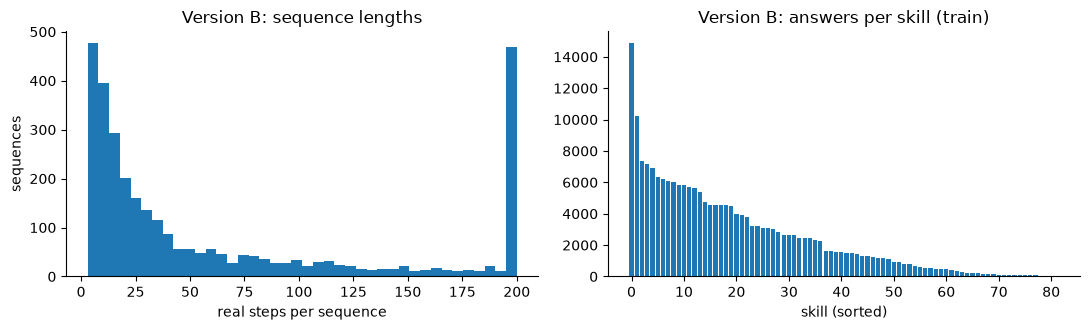

In [7]:
M = d["M_tr"] == 1
L = d["M_tr"].sum(axis=1)
steps = pd.read_csv(B / "dkt_processed/dkt_processed_steps.csv", nrows=8)
print("First rows of dkt_processed_steps.csv:"); print(steps.to_string(index=False))
assert bool((d["X_tr"][M] == d["S_tr"][M] + N * d["C_tr"][M]).all()), "encoding broken"
print("encoding x = skill + N*correct holds for every real step")

cnt = np.bincount(d["S_tr"][M], minlength=N)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].hist(L, bins=40); ax[0].set_xlabel("real steps per sequence"); ax[0].set_ylabel("sequences"); ax[0].set_title("Version B: sequence lengths")
ax[1].bar(range(N), np.sort(cnt)[::-1]); ax[1].set_xlabel("skill (sorted)"); ax[1].set_title("Version B: answers per skill (train)")
plt.tight_layout(); plt.show()

In [8]:
a_ids = set(skill_map.skill_id)
b_ids = set(pd.read_csv(B / "dkt_processed/skill_map.csv").skill_id_original)
print(f"skill ids: A has {len(a_ids)}, B has {len(b_ids)}, in both {len(a_ids & b_ids)}, only in B {len(b_ids - a_ids)}")

skill ids: A has 149, B has 82, in both 66, only in B 16


**Reading it.** Only 66 skill ids are shared and B has 16 that A does not, so the two versions come from **different source files** and their
scores are not comparable.

## 3. MathDial (Socratic model)

2,861 tutor-student dialogues where a teacher guides a (simulated) student who made a mistake on a maths word problem. Every tutor reply
carries MathDial's own label.

**What the classes mean.** `probing` asks a question that exposes the error; `focus` points at the key step; `generic` is
encouragement or filler; `telling` states the answer or the fix. A Socratic tutor should produce the first two, so we keep `telling`
replies in the data but flag them.

**Preprocessing and why**

| Step | Why |
|---|---|
| One example per tutor reply (problem, hidden solution, wrong student solution, history, then target) | The model learns "next tutor message given the conversation", which is exactly its job at run time. |
| Flag `telling` replies and replies containing the final answer (`keep = false`) | Training on them would teach the model to give answers away. |
| Keep MathDial's own test set | Results stay comparable with the paper. |
| Cut validation from train **by problem** | The same problem appears in several dialogues; a random cut would put near-identical conversations on both sides. |

In [9]:
M = {s: jsonl(P / f"mathdial/{s}.jsonl") for s in ("train", "val", "test")}
acts = pd.DataFrame({s: Counter(r["act"] for r in rows) for s, rows in M.items()})
acts["total"] = acts.sum(axis=1)
print("Tutor-reply labels per split:"); print(acts.loc[["probing", "focus", "generic", "telling"]].to_string())
summary = pd.DataFrame({s: {"dialogues": len({(r["qid"]) for r in rows}), "examples": len(rows),
                            "kept": sum(r["keep"] for r in rows), "leak the answer": sum(r["leaks_answer"] for r in rows)}
                        for s, rows in M.items()}).T
summary

Tutor-reply labels per split:
         train  val  test  total
probing   2987  302   947   4236
focus     5000  537  1252   6789
generic   3165  375   890   4430
telling   2228  261   597   3086


,dialogues,examples,kept,leak the answer
train,932,13380,10797,838
val,103,1475,1182,81
test,394,3686,2972,275


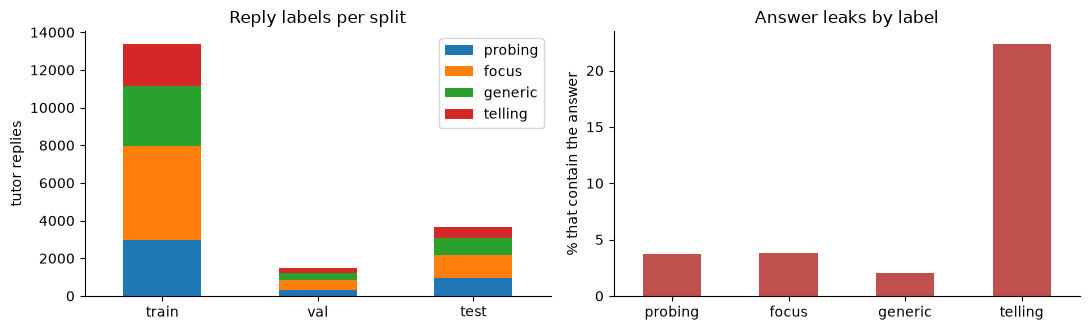

In [10]:
leak = pd.Series({a: np.mean([r["leaks_answer"] for rows in M.values() for r in rows if r["act"] == a]) for a in acts.index})
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
acts.loc[["probing", "focus", "generic", "telling"], ["train", "val", "test"]].T.plot.bar(stacked=True, ax=ax[0], rot=0)
ax[0].set_title("Reply labels per split"); ax[0].set_ylabel("tutor replies")
(leak * 100).loc[["probing", "focus", "generic", "telling"]].plot.bar(ax=ax[1], rot=0, color="#c0504d")
ax[1].set_ylabel("% that contain the answer"); ax[1].set_title("Answer leaks by label")
plt.tight_layout(); plt.show()

In [11]:
for act in ("probing", "focus", "generic", "telling"):
    r = next(r for r in M["train"] if r["act"] == act)
    print(f"[{act}] keep={r['keep']} leaks_answer={r['leaks_answer']}")
    print("   last student message:", [m for m in r["messages"] if m["role"] == "user"][-1]["content"][:160] if any(m["role"] == "user" for m in r["messages"]) else "(none yet)")
    print("   target tutor reply  :", r["target"][:200]); print()
print("Fields of one example:", list(M["train"][0].keys()))

[probing] keep=True leaks_answer=False
   last student message: The aquarium has a volume of 4 x 6 x 3 = 72 cubic feet.
When Nancy fills it halfway, she fills it with 72/2 = 36 cubic feet of water.
When the cat spills half o
   target tutor reply  : Steven, If you had 4 of something and tripled that amount, how much would you have?

[focus] keep=True leaks_answer=False
   last student message: Yes, I could count the number of slices of each type of pie and then divide by the number of pieces in each pie. For shepherd's pie, I would divide 208 by 4 to 
   target tutor reply  : But there are always 4 slices in a shepherd's pie, so using the total number of slices might not be helpful.  Are there are any other quantities you could use to divide by the slices in the pie?

[generic] keep=True leaks_answer=False
   last student message: She would have 54 cubic feet of water.
   target tutor reply  : Exactly correct!

[telling] keep=False leaks_answer=False
   last student message: It will ta

**Reading it.** 3,086 of 18,541 replies (17%) are `telling`, and 1,194 replies contain the final answer. They are flagged,
not deleted, so we can still measure how often a model leaks. 283 of the 394 test problems also appear in train (MathDial's own split), so
a score on genuinely unseen problems must be reported separately.

## 4. Chat corpus, version B (MathDial + SocraTeach)

In [12]:
roles, src, first = Counter(), Counter(), Counter()
with open(B / "socratic_tutor_combined.jsonl", encoding="utf8") as f:
    for line in f:
        r = json.loads(line); src[r["source"]] += 1
        first[(r["source"], r["messages"][0]["role"])] += 1
        for m in r["messages"]: roles[(r["source"], m["role"])] += 1
print("conversations:", dict(src))
print(pd.Series(roles).unstack(fill_value=0))
print("first role of each conversation:", dict(first))

conversations: {'soctrateach': 35151, 'mathdial': 2262}
             assistant  system    user
mathdial         14448    2262   13410
soctrateach     185600       0  150451
first role of each conversation: {('soctrateach', 'assistant'): 35151, ('mathdial', 'system'): 2262}


**Reading it.** The 2,262 MathDial conversations are the same dialogues as version A's train + validation sets, so training on this
file and validating on version A's validation split would leak. SocraTeach dialogues all start with a tutor message and have no problem
statement in the messages. Both are noted in the report as things to fix before fine-tuning.

## 5. NCERT text (study material for search)

Maths and Science, classes 6-10, from ncert.nic.in. The text is not redistributed (the books are public but not ours to republish), so
only counts and a short excerpt are shown.

**Preprocessing and why**

| Step | Why |
|---|---|
| Extract text page by page | Keeps the page number so the tutor can cite "chapter X, page Y". |
| Clean headers, footers and stray characters | They add noise to search. |
| Split into chunks of up to 250 words | Small enough to retrieve precisely, large enough to hold one idea. |
| Tag each chunk with subject, class, chapter, page | Needed for citations and to filter by level. |

In [13]:
ncert = json.load(open(P / "ncert/stats.json"))
books = pd.DataFrame(ncert["books"]).T
books.index.name = "book"
print("chunks:", ncert["chunks"], "| pages:", ncert["pages"], "| kept:", ncert["pages_kept"], "| failed:", ncert["pages_failed"])
books

chunks: 3164 | pages: 2401 | kept: 2353 | failed: 4


,chapters,chunks
book,,
maths_class10,14,253
maths_class6,10,475
maths_class7,8,369
maths_class8,13,213
maths_class9,8,301
science_class10,13,217
science_class6,12,345
science_class7,12,330
science_class8,13,181


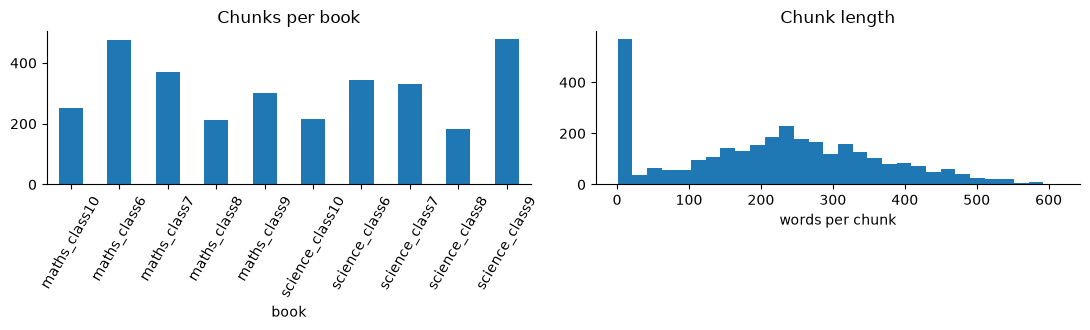

Sample chunk fields: {'id': 'ncert-maths-10-06-p017-0', 'course': 'ncert-maths', 'subject': 'maths', 'class': 10, 'level': 10, 'chapter': 6, 'page': 17, 'source': 'NCERT Maths Class 10, chapter 6', 'text': 'TRIANGLES 89 Fig. 6.26 Cut DP = AB and DQ = AC and join PQ. It can be seen that DPPE = DQQF and PQ || EF (How?) So, \uf0d0 P = \uf0d0 E and \uf0d0 Q = \uf0d0 F. Therefore, DPDE = D...'}
share of chunks under 50 words: 20.2%


In [14]:
chunks = jsonl(P / "ncert/chunks.jsonl")
wc = pd.Series([len(c["text"].split()) for c in chunks])
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
books["chunks"].plot.bar(ax=ax[0], rot=60); ax[0].set_title("Chunks per book")
ax[1].hist(wc, bins=30); ax[1].set_xlabel("words per chunk"); ax[1].set_title("Chunk length")
plt.tight_layout(); plt.show()
c = chunks[100]
print("Sample chunk fields:", {k: (v if k != "text" else v[:160] + "...") for k, v in c.items()})
print("share of chunks under 50 words: %.1f%%" % (100 * (wc < 50).mean()))

**Reading it.** About 20% of chunks are under 50 words (chapter ends, figure captions). The sample chunk above shows the main known problem:
older Class 8-10 maths books lose symbols and digits in extraction (stray characters, and `80/100` reading `80100`). Those books need a manual
check before being used for search; the course packs lean on the Class 6-7 books but also use Class 8.

## 6. Course packs and our own test scenarios

Hand-written by the team (not downloaded). Packs hold concepts, prerequisite links and practice questions. The scenarios test the tutor's
decisions and are never used for training.

               prerequisites  questions  concepts
pack                                             
ncert-maths               13         52        10
ncert-science              6         18         6


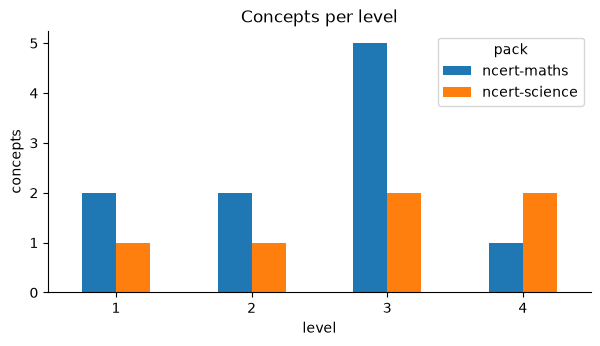

In [15]:
rows = []
for name in ("ncert-maths", "ncert-science"):
    pack = json.load(open(P / f"course_packs/{name}.json", encoding="utf8"))
    for c in pack["concepts"]:
        rows.append({"pack": name, "concept": c["id"], "level": c["level"], "prerequisites": len(c["prerequisites"]),
                     "questions": len(c["questions"]), "materials": len(c["materials"])})
packs = pd.DataFrame(rows)
print(packs.groupby("pack")[["prerequisites", "questions"]].sum().assign(concepts=packs.groupby("pack").size()))
packs.groupby(["pack", "level"]).size().unstack(0).fillna(0).astype(int).plot.bar(rot=0, title="Concepts per level")
plt.ylabel("concepts"); plt.show()

In [16]:
S = A / "test_scenarios"
bt, mc, gr = (jsonl(S / f"{n}.jsonl") for n in ("backtracking", "misconceptions", "guardrails"))
print("backtracking:", dict(Counter(r["type"] for r in bt)))
print("guardrails  :", dict(Counter(r["label"] for r in gr)))
print("misconceptions:", len(mc), "items,", len({r["misconception"] for r in mc}), "kinds")
print()
for r in (bt[1], bt[2]):
    print({k: r[k] for k in ("type", "learner_answer", "weak_concepts", "mastery", "expected_first_action")})
print("-> same answer, different mastery, so different first action (probe vs hint)")
print(); print(mc[0]); print(); print(gr[25])

backtracking: {'correct': 16, 'careless_mistake': 16, 'success_after_hint': 16, 'gap_one_level': 19, 'gap_two_levels': 15}
guardrails  : {'on_topic': 15, 'off_topic': 15, 'answer_request': 17}
misconceptions: 32 items, 24 kinds

{'type': 'careless_mistake', 'learner_answer': '121', 'weak_concepts': [], 'mastery': {'multiplication_division': 0.9}, 'expected_first_action': 'probe'}
{'type': 'success_after_hint', 'learner_answer': '121', 'weak_concepts': [], 'mastery': {'multiplication_division': 0.5}, 'expected_first_action': 'hint'}
-> same answer, different mastery, so different first action (probe vs hint)

{'id': 'mc-001', 'course': 'ncert-maths', 'concept': 'percentages', 'question': 'What is 20% of 50?', 'correct_answer': '10', 'wrong_answer': '2.5', 'misconception': 'divides_by_the_percent', 'explanation': 'Divided 50 by 20 instead of finding 20/100 of 50.', 'reviewed_by': None}

{'id': 'gr-026', 'course': 'ncert-science', 'current_concept': 'time_and_speed', 'message': 'What is t

**Why scenarios carry `mastery`.** A slip (wrong answer, high mastery) should get a probe; a real shaky spot (wrong answer, middling mastery) a hint;
a weak prerequisite a backtrack. Without the mastery estimate two of these cases would have identical inputs and different labels, so no tutor could score on both.
The data check `check_data.py` now enforces "same inputs, same label".

## 7. Summary of what the EDA tells us

- **Learner model:** heavily skewed skills, so report per-skill results and compare with a per-skill accuracy baseline. Splits are by student.
- **Socratic model:** about one reply in six is `telling`; flagged, not deleted. Splits are by problem; do not mix version A validation with version B training.
- **Study text:** chunked with citations; older books need manual repair.
- **Evaluation:** our scenarios are small (about 160 items) and written by us, so they test logic, not real learners.